In [1]:
import pandas as pd

## Merging the tables

To make the business questions easier to query, I merged 7 of the 9 tables into one order-item level table (113,425 rows). I started from `orders` and used left joins, so no order was dropped.

| Step | Table added | Join key | Relationship | Rows after join |
|---|---|---|---|---|
| 1 | `customers` | `customer_id` | many-to-one | 99,441 |
| 2 | `order_items` | `order_id` | one-to-many | 113,425 |
| 3 | `products` | `product_id` | many-to-one | 113,425 |
| 4 | `payments` | `order_id` | one-to-many | 113,425 |
| 5 | `reviews` | `order_id` | one-to-many | 113,425 |
| 6 | category translation | `product_category_name` | many-to-one | 113,425 |

Notes:
- `payments` and `reviews` have several rows per order (installments, multiple reviews). I first aggregated each to one row per `order_id` (`payment_total`, `payment_count`, `review_score_avg`, `review_count`). Joining them directly would multiply rows and double-count money.
- 775 orders have no items (603 `unavailable`, 164 `canceled`, 8 in other early statuses), so their item columns are empty. I kept them for the cancellation analysis and exclude them from sales analysis.
- 1,603 item rows have no product category; I labeled them "Unknown" instead of dropping them, since they are real sales.
- 24 rows had categories missing from the translation table (2 categories); I added the English names manually.
- Not merged: `sellers` and `geolocation` (not needed for these questions; `geolocation` has many rows per zip prefix).

In [2]:

orders = pd.read_csv("data/olist_orders_dataset.csv")
customers = pd.read_csv("data/olist_customers_dataset.csv")


In [3]:
len(orders)


99441

In [4]:
len(customers)

99441

In [5]:
merged = orders.merge(customers, on="customer_id", how="left")


In [6]:
merged.shape[0]

99441

In [7]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [8]:
order_items = pd.read_csv("data/olist_order_items_dataset.csv")
order_items.shape[0]

112650

In [9]:
merged_order_items = merged.merge(order_items, on="order_id", how="left")

In [10]:
merged_order_items.shape[0]

113425

In [11]:
merged_order_items["product_id"].isna().sum()

np.int64(775)

In [12]:
merged_order_items[merged_order_items["product_id"].isna()]["order_status"].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [13]:
merged_order_items.shape

(113425, 18)

In [14]:
merged_order_items.dtypes

order_id                          object
customer_id                       object
order_status                      object
order_purchase_timestamp          object
order_approved_at                 object
order_delivered_carrier_date      object
order_delivered_customer_date     object
order_estimated_delivery_date     object
customer_unique_id                object
customer_zip_code_prefix           int64
customer_city                     object
customer_state                    object
order_item_id                    float64
product_id                        object
seller_id                         object
shipping_limit_date               object
price                            float64
freight_value                    float64
dtype: object

In [15]:
products = pd.read_csv("data/olist_products_dataset.csv")
products["product_id"].is_unique

True

In [16]:
merged_products = merged_order_items.merge(products, on="product_id", how="left")

In [17]:
merged_products.shape[0]

113425

In [18]:
merged_products[merged_products["product_id"].notna()]["product_category_name"].isna().sum()


np.int64(1603)

In [19]:
merged_products[merged_products["product_id"].notna()]["product_category_name"].isna().nunique()

2

In [20]:
mask = merged_products["product_category_name"].isna()
null_rows = merged_products[mask & merged_products["product_id"].notna()]

In [21]:
null_rows.nunique()

order_id                         1451
customer_id                      1451
order_status                        5
order_purchase_timestamp         1451
order_approved_at                1447
order_delivered_carrier_date     1387
order_delivered_customer_date    1392
order_estimated_delivery_date     355
customer_unique_id               1445
customer_zip_code_prefix         1319
customer_city                     502
customer_state                     26
order_item_id                       7
product_id                        610
seller_id                         257
shipping_limit_date              1449
price                             404
freight_value                     572
product_category_name               0
product_name_lenght                 0
product_description_lenght          0
product_photos_qty                  0
product_weight_g                  145
product_length_cm                  54
product_height_cm                  49
product_width_cm                   47
dtype: int64

In [22]:
null_rows.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                   1
order_delivered_carrier_date       37
order_delivered_customer_date      66
order_estimated_delivery_date       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
product_category_name            1603
product_name_lenght              1603
product_description_lenght       1603
product_photos_qty               1603
product_weight_g                   17
product_length_cm                  17
product_height_cm                  17
product_width_cm                   17
dtype: int64

In [23]:
payments = pd.read_csv("data/olist_order_payments_dataset.csv")


In [24]:
payments.shape[0]

103886

In [25]:
types_per_order = payments.groupby("order_id")["payment_type"].nunique()
flags = types_per_order > 1
flags.sum()

np.int64(2246)

In [26]:
pay_summary = payments.groupby("order_id").agg(
    payment_total=("payment_value", "sum"),
    payment_count=("payment_sequential", "count"),
).reset_index()

In [27]:
pay_summary["order_id"].is_unique

True

In [28]:
merged_payments = merged_products.merge(pay_summary, on="order_id", how="left")
merged_payments.shape[0]

113425

In [29]:
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")
reviews.shape[0]

99224

In [30]:
reviews["order_id"].is_unique

False

In [31]:
reviews_per_order = reviews.groupby("order_id")["review_id"].nunique()
flags_1 = reviews_per_order > 1
flags_1.sum()

np.int64(547)

In [32]:
reviews_summary = reviews.groupby("order_id").agg(
    review_score_avg=("review_score", "mean"),
    review_count=("review_id", "count"),
).reset_index()

In [33]:
reviews_summary["order_id"].is_unique

True

In [34]:
merged_reviews = merged_payments.merge(reviews_summary, on="order_id", how="left")
merged_reviews.shape[0]

113425

In [35]:
merged_reviews.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'payment_total', 'payment_count', 'review_score_avg', 'review_count'],
      dtype='object')

In [36]:
category = pd.read_csv("data/product_category_name_translation.csv")
category.shape[0]

71

In [37]:
category["product_category_name"].is_unique

True

In [38]:
merged_total = merged_reviews.merge(category, on="product_category_name", how="left")
merged_total.shape[0]

113425

In [39]:
merged_total["product_category_name_english"].isna().sum()

np.int64(2402)

In [40]:
mask = merged_total["product_category_name"].notna() & merged_total["product_category_name_english"].isna()
missing_trans = merged_total[mask]
missing_trans["product_category_name"].value_counts()

product_category_name
portateis_cozinha_e_preparadores_de_alimentos    15
pc_gamer                                          9
Name: count, dtype: int64

In [41]:
fix = {
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_and_food_preparers",
}
merged_total["product_category_name_english"] = merged_total["product_category_name_english"].fillna(
    merged_total["product_category_name"].map(fix)
)

In [42]:
merged_total["product_category_name_english"].isna().sum()

np.int64(2378)

In [43]:
has_item = merged_total["product_id"].notna()
merged_total.loc[has_item, "product_category_name_english"] = (
    merged_total.loc[has_item, "product_category_name_english"].fillna("Unknown")
)

In [44]:
merged_total["product_category_name_english"].isna().sum()

np.int64(775)

In [45]:
merged_total.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'payment_total', 'payment_count', 'review_score_avg', 'review_count',
       'product_category_name_english'],
      dtype='object')

## Q1. Order volume by customer state

Orders are counted as distinct `order_id` per `customer_state` (an order can have several item rows, so row counts would overcount). The state totals add up to 99,441, matching the `orders` table.

**Finding:** Demand is highly concentrated. SP (São Paulo) alone has 41,746 orders (42.0% of the total), followed by RJ (12,852) and MG (11,635). Together, these three southeastern states account for 66.6% of all orders.

**Interpretation:** This is consistent with these being the most populated and economically developed states in Brazil, but this dataset has no population data, so that explanation is an assumption, not a result.

**Use:** It shows where demand is concentrated and could help prioritize regional resources. Order count alone does not show profit.

In [46]:
# 各州订单量

state_orders = merged_total.groupby("customer_state")["order_id"].nunique().sort_values(ascending=False)
state_orders.head(10)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: order_id, dtype: int64

In [66]:
(state_orders.head(3).sum()) / state_orders.sum()

np.float64(0.6660532375981738)

In [67]:
(state_orders.head(1).sum()) / state_orders.sum()

np.float64(0.41980671956235355)

## Q2. Cancellation rate

Computed on the `orders` table (99,441 orders, one row per order), not the merged table, to avoid counting orders with several items more than once.

**Finding:** Cancellations are rare. 625 orders (0.63%) are `canceled`, and 609 (0.61%) are `unavailable` (item not available). 97.0% of orders are `delivered`. I report the two statuses separately because they mean different things; together they are about 1.2%.

**Note:** About 1.7% of orders are still in progress (`shipped`, `invoiced`, `processing`, `created`, `approved`). They are neither delivered nor canceled, so the delivered share is a lower bound of the final fulfillment rate.

In [50]:
orders['order_status'].value_counts(normalize=True)

order_status
delivered      0.970203
shipped        0.011132
canceled       0.006285
unavailable    0.006124
invoiced       0.003158
processing     0.003027
created        0.000050
approved       0.000020
Name: proportion, dtype: float64

In [52]:
orders["order_status"].value_counts(normalize=True)[["canceled", "unavailable"]]

order_status
canceled       0.006285
unavailable    0.006124
Name: proportion, dtype: float64

## Q3. Monthly sales

Sales = sum of item `price` (excludes freight), grouped by the month the order was placed. I use Jan 2017 to Aug 2018 only: the months before and after have almost no orders (e.g. Sep 2016: 267, Sep 2018: 145), so they would distort the trend.

**Finding:**
- Sales peak in Nov 2017 at about 1.01M, then fall back in Dec 2017 (about 0.74M). The peak may be related to Black Friday, but this dataset has no promotion data, so this is an assumption.
- - Sales are higher in 2018: monthly sales stay between about 0.85M and 1.0M from Jan to Aug 2018, compared with 0.12M to 0.67M in Jan to Oct 2017. Comparing the same months (Jan to Aug), 2018 sales are about 2.4 times those of 2017.

**Next step:** Find what drove the 2018 growth (more customers, more orders per customer, or higher prices).

In [53]:
merged_total["order_purchase_timestamp"] = pd.to_datetime(merged_total["order_purchase_timestamp"])

In [63]:
merged_total["month"] = merged_total["order_purchase_timestamp"].dt.to_period("M")
monthly = merged_total.groupby("month")["price"].sum()
monthly

month
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
2018-10          0.00
Freq: M, Name: price, dtype: float64

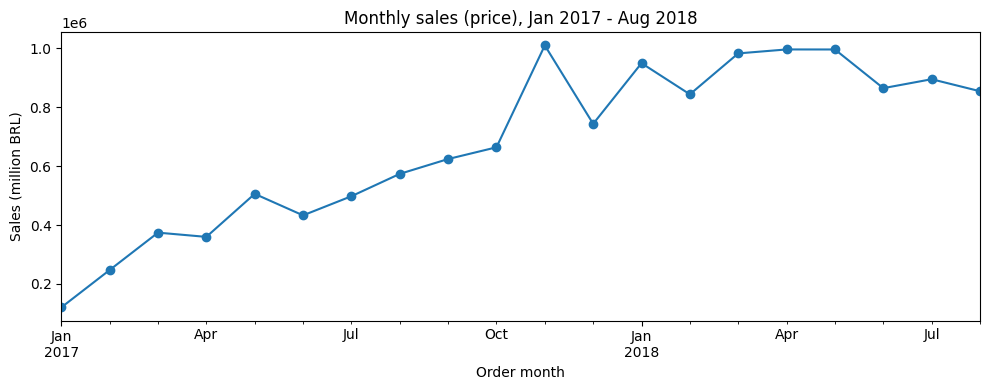

In [69]:
import matplotlib.pyplot as plt

monthly_clean = monthly["2017-01":"2018-08"]
ax = monthly_clean.plot(marker="o", figsize=(10, 4), title="Monthly sales (price), Jan 2017 - Aug 2018")
ax.set_xlabel("Order month")
ax.set_ylabel("Sales (million BRL)")
plt.tight_layout()
plt.show()

In [70]:
y2017 = monthly["2017-01":"2017-08"].sum()
y2018 = monthly["2018-01":"2018-08"].sum()
y2018 / y2017

np.float64(2.372600398576252)

## Q4. Top 10 product categories by sales

Sales = sum of item `price` (excludes freight) per English category name. Orders without items are excluded. Item rows with no category (1,603 rows) are labeled "Unknown" and kept, so they are not dropped from the sales totals.

**Finding:**
- The top three categories are `health_beauty` (about 1.26M), `watches_gifts` (about 1.21M) and `bed_bath_table` (about 1.04M).
- No single category dominates: the largest, `health_beauty`, is 9.3% of total sales. Sales fall off gradually from rank 1 to rank 10 (about 0.49M). The top 3 categories together account for 25.8% of sales and the top 10 for 62.4%; the remaining categories (70+ in total) share the other 38%.
- "Unknown" is not in the top 10, so missing categories do not distort the ranking.

**Note:** Only the top 10 are shown; the remaining categories form a long tail that I did not examine.

In [ ]:
category_ranking = merged_total.groupby("product_category_name_english")["price"].sum().sort_values(ascending=False).head(10)
category_ranking


product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64

In [71]:
category_ranking / merged_total["price"].sum()

product_category_name_english
health_beauty            0.092607
watches_gifts            0.088658
bed_bath_table           0.076296
sports_leisure           0.072695
computers_accessories    0.067097
furniture_decor          0.053692
cool_stuff               0.046741
housewares               0.046517
auto                     0.043609
garden_tools             0.035703
Name: price, dtype: float64

In [76]:
(category_ranking.head(3) / merged_total["price"].sum()).sum()

np.float64(0.2575608791157467)